In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in r18b05lexa_r60d05gal4_analysis.py next to this notebook
# (run it as a script to regenerate everything: python r18b05lexa_r60d05gal4_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import r18b05lexa_r60d05gal4_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head(40)

,date,fly,session,fictrac_scan_num,fictrac_file,condition,scan_type,usable,notes,fly_id
0,11_07_2024,fly1,baseline-000,0,fictrac-20240711_112205.dat,remap,baseline,1.0,NaN,11_07_2024_fly1_condition_remap
1,11_07_2024,fly1,remap_0deg-001,1,fictrac-20240711_112205.dat,remap,remap_0deg,1.0,NaN,11_07_2024_fly1_condition_remap
2,11_07_2024,fly1,post_0deg-002,2,fictrac-20240711_112205.dat,remap,post_0deg,1.0,NaN,11_07_2024_fly1_condition_remap
3,11_07_2024,fly1,remap_180deg-004,4,fictrac-20240711_112205.dat,remap,remap_180deg,1.0,NaN,11_07_2024_fly1_condition_remap
4,11_07_2024,fly1,post_180deg-006,6,fictrac-20240711_112205.dat,remap,post_180deg,1.0,NaN,11_07_2024_fly1_condition_remap
5,15_07_2024,fly1,baseline-002,2,fictrac-20240715_084728.dat,remap,baseline,1.0,NaN,15_07_2024_fly1_condition_remap
6,15_07_2024,fly1,remap_0deg-003,3,fictrac-20240715_084728.dat,remap,remap_0deg,1.0,NaN,15_07_2024_fly1_condition_remap
7,15_07_2024,fly1,post_0deg-005,5,fictrac-20240715_084728.dat,remap,post_0deg,1.0,NaN,15_07_2024_fly1_condition_remap
8,15_07_2024,fly1,remap_180deg-006,6,fictrac-20240715_084728.dat,remap,remap_180deg,1.0,NaN,15_07_2024_fly1_condition_remap
9,15_07_2024,fly1,post_180deg-007,7,fictrac-20240715_084728.dat,remap,post_180deg,1.0,NaN,15_07_2024_fly1_condition_remap


## Optogenetic responses

opto_window_tests


,comparison,U,p,p_holm
0,EL stim vs no CsChrimson,125.0,0.000224,0.000448
1,EL stim vs no visual cue,56.0,0.437797,0.437797


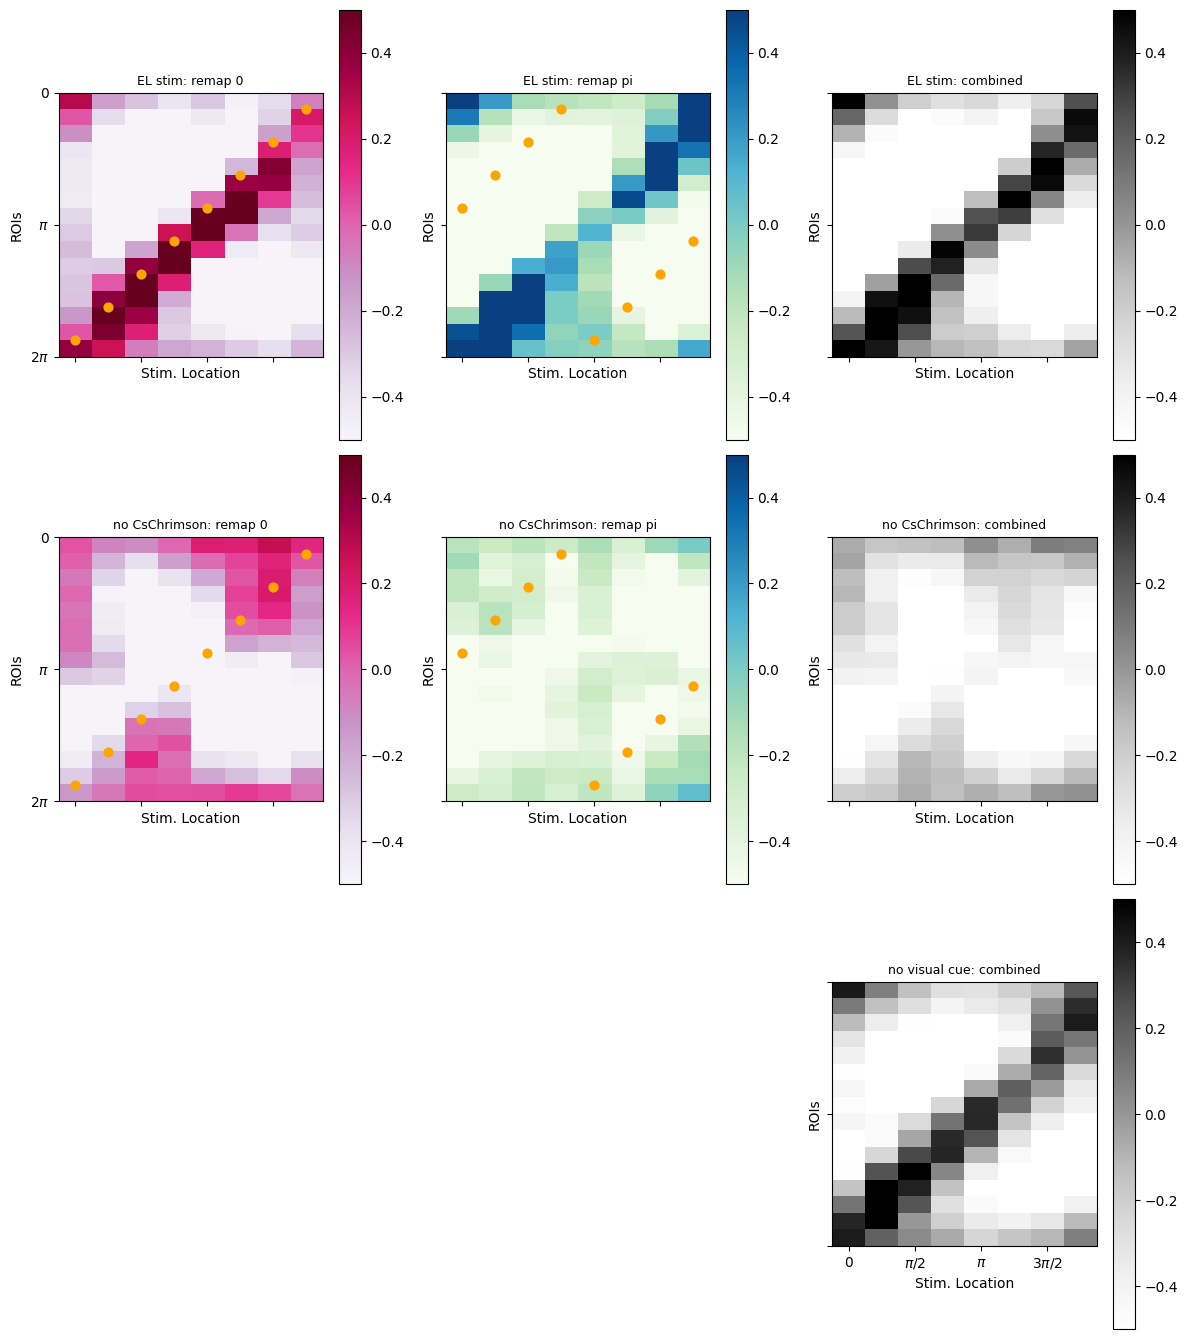

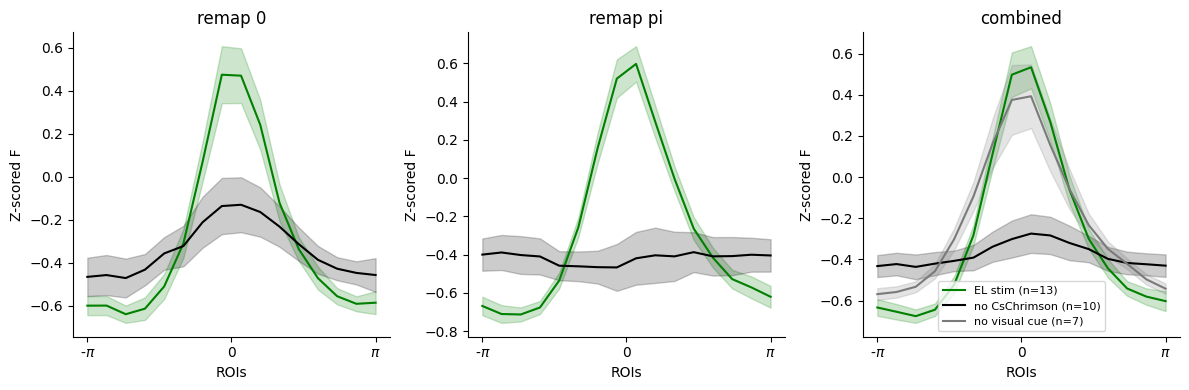

In [3]:
aligned_opto, opto_tables = ana.opto_analysis(sess_manager)
for name, table in opto_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Offset remapping

remap remap 0 -0.038657162323625135
remap remap 180 3.1044212673013076
no_chrimson remap 0 0.37106377823911274
no_chrimson remap 180 -0.21297812457618695
remapping_error_tests


,family,comparison,n,W,p,p_holm
0,error vs chance,EL stim,13.0,0.0,0.000244,0.000732
1,error vs chance,no CsChrimson,9.0,20.0,0.820312,1.000000
2,error vs chance,no visual cue,10.0,24.0,0.769531,1.000000
3,error between groups,EL stim vs no CsChrimson,NaN,0.0,0.000107,0.000127
4,error between groups,EL stim vs no visual cue,NaN,0.0,0.000063,0.000127


mean_offsets


,group,scan_type,n_flies,mean_offset,mean_vec_len
0,remap,baseline,13,0.331027,0.243018
1,remap,post_0deg,13,-0.038657,0.441368
2,remap,post_180deg,13,3.104421,0.411809
3,no_chrimson,baseline,10,-0.013164,0.273383
4,no_chrimson,post_0deg,10,0.371064,0.286318
5,no_chrimson,post_180deg,9,-0.212978,0.233346
6,novis_control,baseline,10,-0.869826,0.050918
7,novis_control,post_novis1,10,-0.960694,0.225536
8,novis_control,post_novis2,10,-0.555283,0.159105


n_flies


,group,n_flies
0,remap,14
1,no_chrimson,10
2,novis_control,10


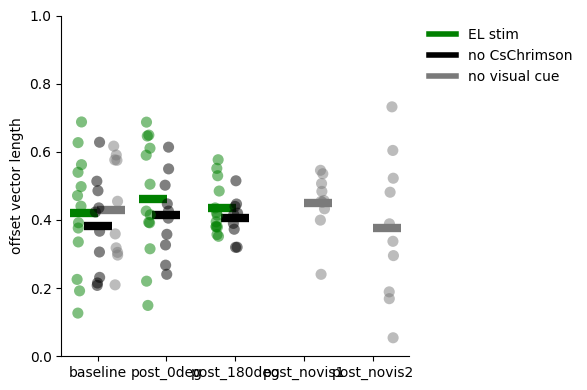

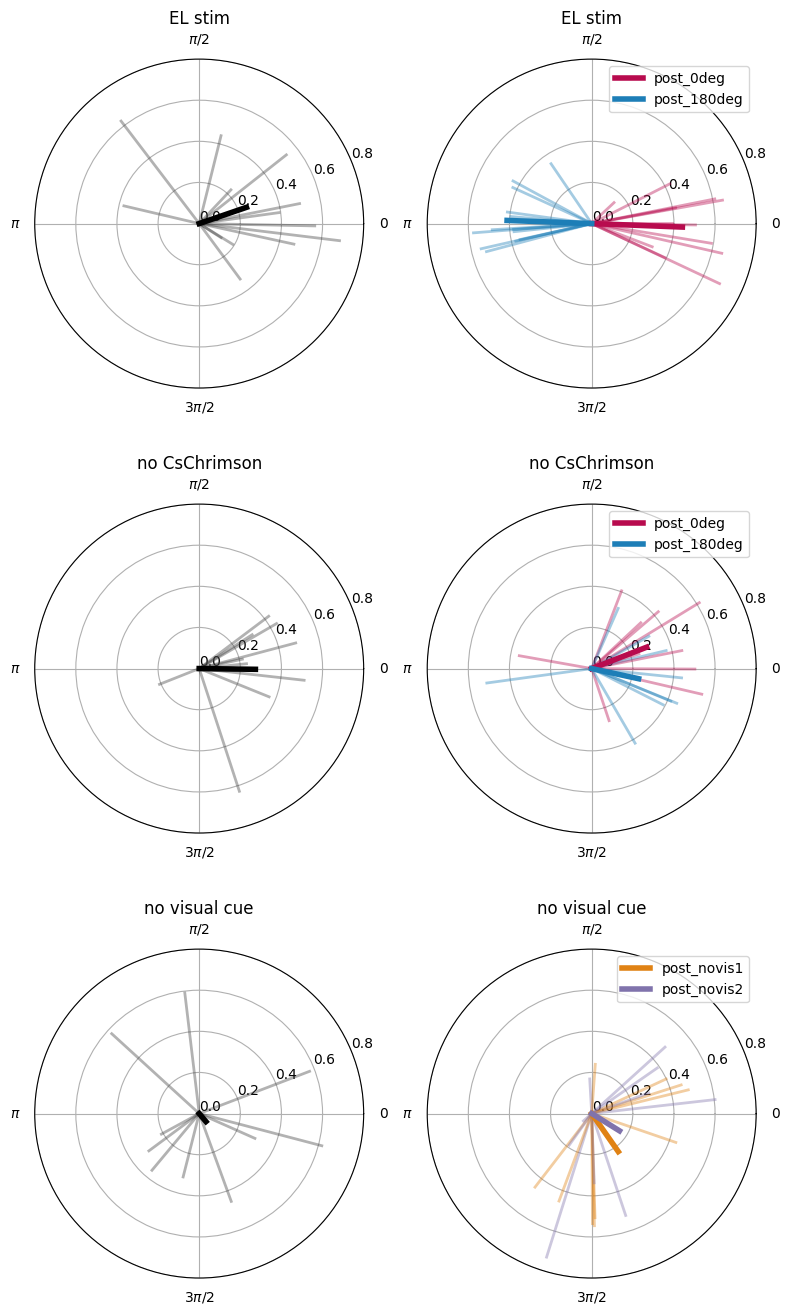

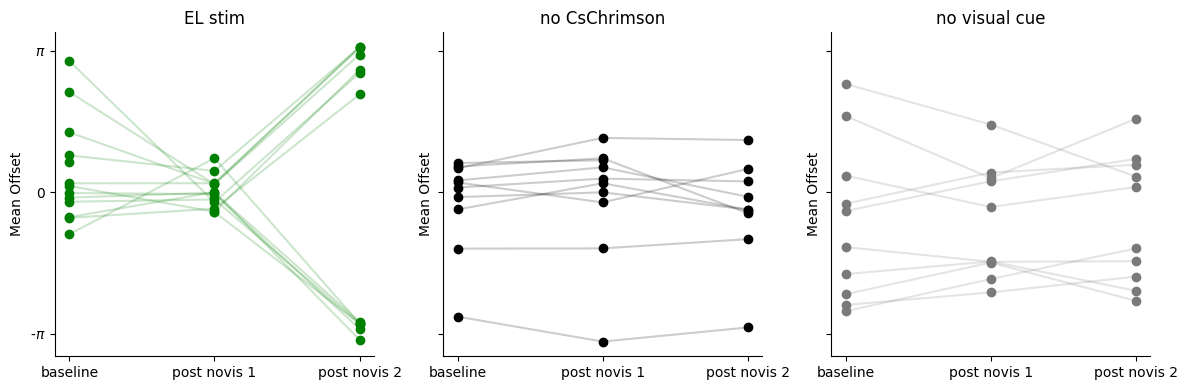

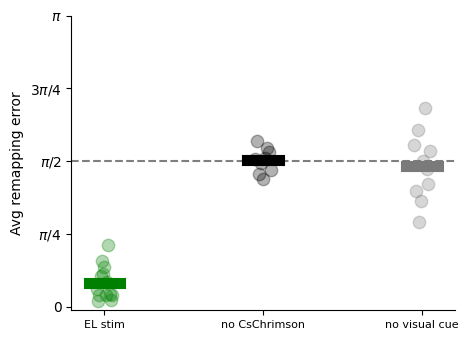

In [4]:
offset_summary, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Heatmaps and offset histograms of every fly

In [5]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

21